<a href="https://colab.research.google.com/github/HannaVar1/belhard_project/blob/main/03_capture_regression_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Цель эксперимента — предсказать игровую характеристику capture_rate по боевым статам, росту и весу покемона. Несмотря на дискретность значений, задача рассматривается как регрессия, поскольку величина отклонения прогноза имеет значение.

Сравниваются SVR с RBF-ядром и многослойный персептрон PyTorch. Прогнозы медианой и средним обучающей выборки используются как baseline. Основная метрика — MAE; дополнительные — RMSE и R². Разбиение выполняется по эволюционным цепочкам, чтобы оценить перенос на незнакомые семейства.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path
import copy
import random

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from IPython.display import display

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

SEED = 42

FEATURES = [
    "hp", "attack", "defense",
    "sp_attack", "sp_defense", "speed",
    "height_m", "weight_kg",
]

TARGET = "capture_rate"
GROUP = "evolution_chain_id"

DATA_PATH = Path(
    "/content/drive/MyDrive/datasets/pokemon_complete.csv"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/regression_results_A"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_EPOCHS = 300
PATIENCE = 25
BATCH_SIZE = 32
LEARNING_RATE = 0.001
DEVICE = torch.device("cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")


def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


def regression_metrics(y_true, prediction):
    return {
        "MAE": mean_absolute_error(y_true, prediction),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, prediction)
        ),
        "R2": r2_score(y_true, prediction),
        "outside_0_255": int(
            ((prediction < 0) | (prediction > 255)).sum()
        ),
    }


if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Файл не найден: {DATA_PATH}")

raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

required = [
    "pokedex_number", "name", GROUP, TARGET, *FEATURES
]

missing = set(required) - set(raw.columns)

if missing:
    raise ValueError(f"Отсутствуют столбцы: {sorted(missing)}")

raw["pokedex_number"] = pd.to_numeric(
    raw["pokedex_number"], errors="raise"
)

# Для этого CSV: основные записи без альтернативных форм.
df = raw.loc[
    raw["pokedex_number"].between(1, 1025)
].copy().reset_index(drop=True)

if df.empty:
    raise ValueError("После отбора выборка пуста")

if not df["pokedex_number"].is_unique:
    raise ValueError("Обнаружены повторяющиеся ID")

numeric_columns = [GROUP, TARGET, *FEATURES]

df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric, errors="raise"
)

if df[numeric_columns].isna().any().any():
    raise ValueError(
        "Обнаружены пропуски:\n"
        + df[numeric_columns].isna().sum().to_string()
    )

if not np.isfinite(
    df[numeric_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Обнаружены бесконечные значения")

if (df[FEATURES] < 0).any().any():
    raise ValueError("Отрицательные значения признаков")

if not df[TARGET].between(0, 255).all():
    raise ValueError("Capture rate вне диапазона 0–255")

print("Объектов:", len(df))
print("Эволюционных цепочек:", df[GROUP].nunique())
print("Уникальных значений target:", df[TARGET].nunique())

display(df[FEATURES + [TARGET]].describe().round(2))

display(
    df[TARGET].value_counts()
    .sort_index()
    .to_frame("count")
)

print(
    "Пропусков нет: SimpleImputer не используется."
)

Объектов: 1025
Эволюционных цепочек: 541
Уникальных значений target: 38


,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,capture_rate
count,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00
mean,70.18,77.52,72.51,70.08,70.21,67.19,1.21,66.99,95.45
std,26.63,29.78,29.29,29.66,26.64,28.72,1.25,121.27,75.99
min,1.00,5.00,5.00,10.00,20.00,5.00,0.10,0.10,3.00
25%,50.00,55.00,50.00,47.00,50.00,45.00,0.50,8.50,45.00
50%,68.00,75.00,70.00,65.00,67.00,65.00,1.00,28.00,60.00
75%,85.00,100.00,90.00,90.00,86.00,88.00,1.50,70.00,140.00
max,255.00,181.00,230.00,173.00,230.00,200.00,20.00,999.90,255.00


,count
capture_rate,
3,76
5,3
6,4
10,11
15,1
25,19
30,33
35,1
45,313


Пропусков нет: SimpleImputer не используется.


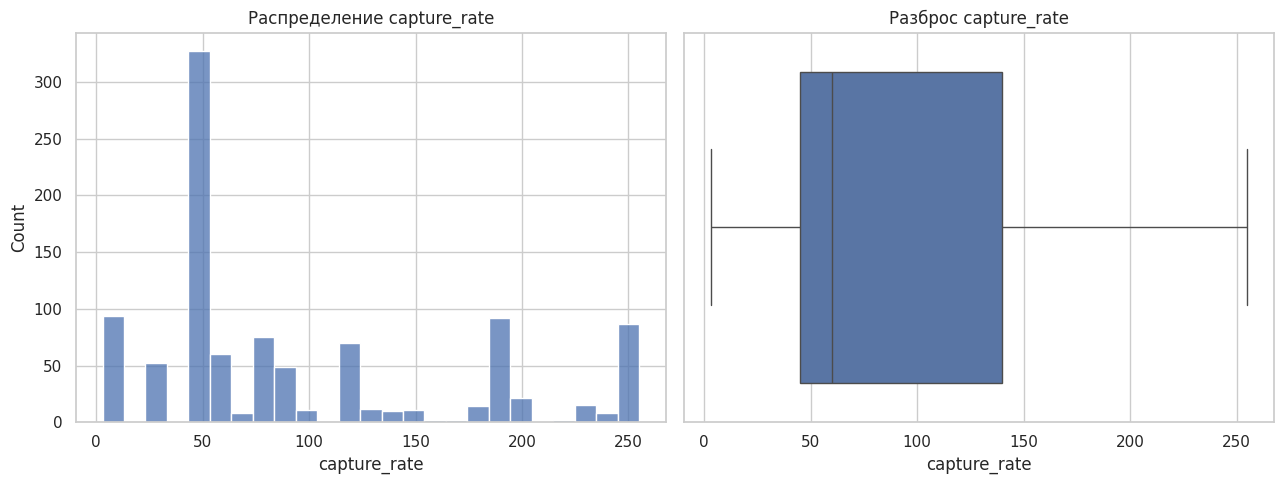

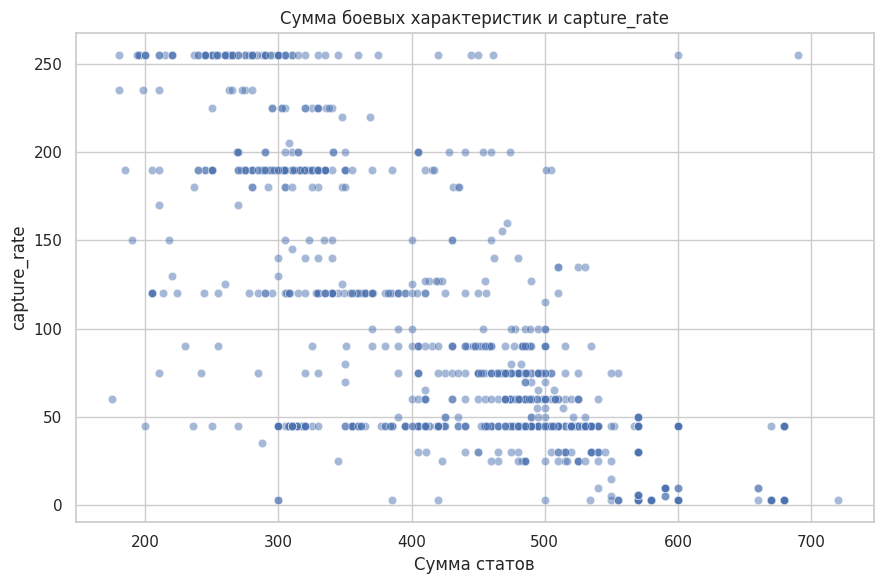

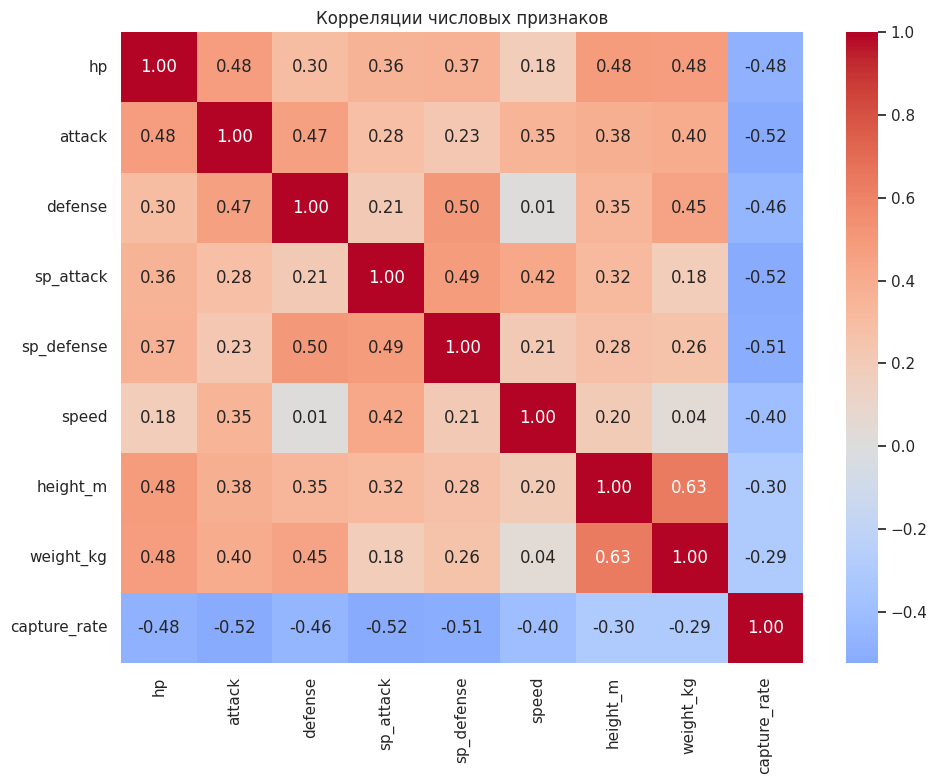

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=df,
    x=TARGET,
    bins=25,
    ax=axes[0],
)
axes[0].set_title("Распределение capture_rate")

sns.boxplot(
    data=df,
    x=TARGET,
    ax=axes[1],
)
axes[1].set_title("Разброс capture_rate")

save_plot("01_target_distribution.png")

# Сумма рассчитывается из используемых статов.
stat_columns = FEATURES[:6]

eda_data = df.copy()
eda_data["stat_sum"] = eda_data[stat_columns].sum(axis=1)

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=eda_data,
    x="stat_sum",
    y=TARGET,
    alpha=0.5,
)
plt.title("Сумма боевых характеристик и capture_rate")
plt.xlabel("Сумма статов")
save_plot("02_stats_vs_capture_rate.png")

plt.figure(figsize=(10, 8))
sns.heatmap(
    df[FEATURES + [TARGET]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Корреляции числовых признаков")
save_plot("03_correlations.png")

# Корреляция показывает только линейную связь,
# а не причинное влияние и не всю предсказательную зависимость.

Создано и сохранено новое разбиение
Размеры и распределение target:


,split,rows,row_share,chains,target_mean,target_median,target_std,target_min,target_max
0,train,662,0.65,345,95.89,60.0,76.19,3,255
1,validation,160,0.16,87,87.66,55.0,70.84,3,255
2,test,203,0.20,109,100.17,60.0,79.09,3,255


Квартили target:


,train,validation,test
count,662.00,160.00,203.00
mean,95.89,87.66,100.17
std,76.19,70.84,79.09
min,3.00,3.00,3.00
25%,45.00,45.00,45.00
50%,60.00,55.00,60.00
75%,138.75,120.00,190.00
max,255.00,255.00,255.00


Количество объектов по диапазонам:


,train,validation,test
capture_rate,,,
0–30,93,24,30
31–100,342,90,99
101–200,152,34,48
201–255,75,12,26


Доли по диапазонам, %:


,train,validation,test
capture_rate,,,
0–30,14.0,15.0,14.8
31–100,51.7,56.2,48.8
101–200,23.0,21.2,23.6
201–255,11.3,7.5,12.8


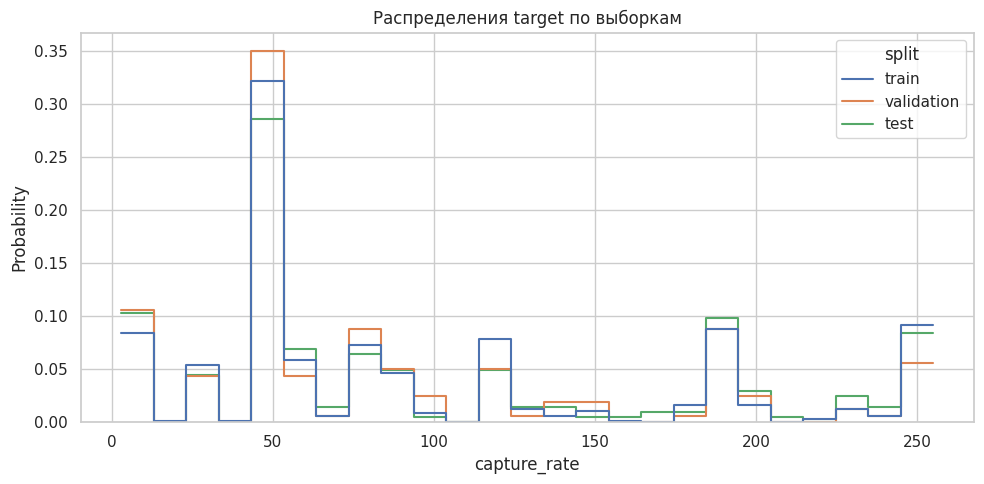

In [ ]:
SPLIT_PATH = OUTPUT_DIR / "split.csv"

if SPLIT_PATH.is_file():
    saved_split = pd.read_csv(
        SPLIT_PATH, encoding="utf-8-sig"
    )

    required_split = [
        "pokedex_number", GROUP, TARGET, "split"
    ]

    if not set(required_split).issubset(saved_split.columns):
        raise ValueError("Некорректная структура split.csv")

    if saved_split[required_split].isna().any().any():
        raise ValueError("Пропуски в split.csv")

    for column in ["pokedex_number", GROUP, TARGET]:
        saved_split[column] = pd.to_numeric(
            saved_split[column], errors="raise"
        )

    saved_split["split"] = (
        saved_split["split"].astype(str).str.strip()
    )

    if not saved_split["pokedex_number"].is_unique:
        raise ValueError("Повторяющиеся ID в split.csv")

    if set(saved_split["split"]) != {
        "train", "validation", "test"
    }:
        raise ValueError("Некорректные названия частей")

    if set(saved_split["pokedex_number"]) != set(df["pokedex_number"]):
        raise ValueError("Набор объектов изменился относительно split")

    reference = saved_split.set_index("pokedex_number")
    current = df.set_index("pokedex_number")

    for column in [GROUP, TARGET]:
        old = reference[column].reindex(current.index)

        if not old.eq(current[column]).fillna(False).all():
            raise ValueError(
                f"Поле {column} изменилось относительно split"
            )

    parts = {
        name: current.loc[
            saved_split.loc[
                saved_split["split"] == name,
                "pokedex_number",
            ].tolist()
        ].reset_index()
        for name in ["train", "validation", "test"]
    }

    print("Используется сохранённое разбиение")

else:
    outer = GroupShuffleSplit(
        n_splits=1,
        test_size=0.2,
        random_state=SEED,
    )

    trainval_idx, test_idx = next(
        outer.split(df, groups=df[GROUP])
    )

    trainval = df.iloc[trainval_idx].copy()
    test = df.iloc[test_idx].copy()

    inner = GroupShuffleSplit(
        n_splits=1,
        test_size=0.2,
        random_state=SEED,
    )

    train_idx, val_idx = next(
        inner.split(trainval, groups=trainval[GROUP])
    )

    train = trainval.iloc[train_idx].copy()
    val = trainval.iloc[val_idx].copy()

    parts = {
        "train": train,
        "validation": val,
        "test": test,
    }

    saved_split = pd.concat([
        part[["pokedex_number", GROUP, TARGET]].assign(split=name)
        for name, part in parts.items()
    ])

    saved_split.to_csv(
        SPLIT_PATH,
        index=False,
        encoding="utf-8-sig",
    )

    print("Создано и сохранено новое разбиение")


train = parts["train"]
val = parts["validation"]
test = parts["test"]

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = set(parts[first][GROUP]) & set(parts[second][GROUP])

    if overlap:
        raise ValueError(
            f"Пересечение цепочек: {first}/{second}"
        )

all_ids = pd.concat([
    part["pokedex_number"] for part in parts.values()
])

if (
    not all_ids.is_unique
    or len(all_ids) != len(df)
    or set(all_ids) != set(df["pokedex_number"])
):
    raise ValueError("Некорректное распределение объектов")

summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(part),
        "row_share": len(part) / len(df),
        "chains": part[GROUP].nunique(),
        "target_mean": part[TARGET].mean(),
        "target_median": part[TARGET].median(),
        "target_std": part[TARGET].std(),
        "target_min": part[TARGET].min(),
        "target_max": part[TARGET].max(),
    }
    for name, part in parts.items()
])

print("Размеры и распределение target:")
display(summary.round(2))

summary.to_csv(
    OUTPUT_DIR / "split_summary.csv",
    index=False,
)

print("Квартили target:")
display(pd.DataFrame({
    name: part[TARGET].describe()
    for name, part in parts.items()
}).round(2))


# Заранее фиксируем аналитические диапазоны.
RANGE_BINS = [-1, 30, 100, 200, 255]
RANGE_LABELS = ["0–30", "31–100", "101–200", "201–255"]

range_counts = pd.DataFrame({
    name: pd.cut(
        part[TARGET],
        bins=RANGE_BINS,
        labels=RANGE_LABELS,
    ).value_counts(sort=False)
    for name, part in parts.items()
}).reindex(RANGE_LABELS).fillna(0).astype(int)

print("Количество объектов по диапазонам:")
display(range_counts)

print("Доли по диапазонам, %:")
display(
    range_counts.div(range_counts.sum(axis=0), axis=1)
    .mul(100)
    .round(1)
)

plot_data = pd.concat([
    part[[TARGET]].assign(split=name)
    for name, part in parts.items()
])

plt.figure(figsize=(10, 5))
sns.histplot(
    data=plot_data,
    x=TARGET,
    hue="split",
    bins=25,
    stat="probability",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title("Распределения target по выборкам")
save_plot("04_target_by_split.png")

# Эти проверки нужны для аудита протокола.
# Не меняем split ради улучшения результатов на test.

In [ ]:
baseline_median = DummyRegressor(strategy="median")
baseline_mean = DummyRegressor(strategy="mean")

baseline_median.fit(train[FEATURES], train[TARGET])
baseline_mean.fit(train[FEATURES], train[TARGET])

print(
    "Прогноз медианного baseline:",
    baseline_median.predict(val[FEATURES])[0],
)
print(
    "Прогноз среднего baseline:",
    baseline_mean.predict(val[FEATURES])[0],
)

svr_models = {}
svr_rows = []

for C in [0.1, 1, 10, 100]:
    for gamma in ["scale", 0.01, 0.1]:
        for epsilon in [0.01, 0.1, 0.2]:
            candidate = TransformedTargetRegressor(
                regressor=make_pipeline(
                    StandardScaler(),
                    SVR(
                        kernel="rbf",
                        C=C,
                        gamma=gamma,
                        epsilon=epsilon,
                    ),
                ),
                transformer=StandardScaler(),
            )

            # Обе стандартизации обучаются только на train.
            candidate.fit(train[FEATURES], train[TARGET])
            prediction = candidate.predict(val[FEATURES])

            key = (float(C), str(gamma), float(epsilon))
            svr_models[key] = candidate

            svr_rows.append({
                "C": C,
                "gamma": str(gamma),
                "epsilon_scaled_target": epsilon,
                **regression_metrics(val[TARGET], prediction),
            })

svr_search = pd.DataFrame(svr_rows).sort_values(
    "MAE",
    ascending=True,
    kind="stable",
)

print("Подбор SVR на validation:")
display(svr_search.head(15).round(4))

best_row = svr_search.iloc[0]

best_key = (
    float(best_row["C"]),
    best_row["gamma"],
    float(best_row["epsilon_scaled_target"]),
)

svr = svr_models[best_key]

print("Выбранные параметры SVR:")
display(best_row.to_frame("value"))

svr_search.to_csv(
    OUTPUT_DIR / "svr_validation_search.csv",
    index=False,
)

Прогноз медианного baseline: 60.0
Прогноз среднего baseline: 95.89425981873111
Подбор SVR на validation:


,C,gamma,epsilon_scaled_target,MAE,RMSE,R2,outside_0_255
22,10.0,0.01,0.10,35.6466,51.3008,0.4723,2
13,1.0,0.01,0.10,35.7735,50.5981,0.4866,2
12,1.0,0.01,0.01,35.8468,50.6373,0.4858,4
21,10.0,0.01,0.01,35.9043,51.6504,0.4651,5
23,10.0,0.01,0.20,35.9228,51.5109,0.4679,4
14,1.0,0.01,0.20,36.0017,50.5611,0.4874,1
15,1.0,0.1,0.01,36.1339,52.7245,0.4426,1
32,100.0,0.01,0.20,36.4185,52.4253,0.4489,7
9,1.0,scale,0.01,36.4763,53.6003,0.4239,2
31,100.0,0.01,0.10,36.6737,52.4767,0.4478,5


Выбранные параметры SVR:


,value
C,10.0
gamma,0.01
epsilon_scaled_target,0.1
MAE,35.646617
RMSE,51.300818
R2,0.472268
outside_0_255,2


Epoch   1 | train MAE=44.22 | validation MAE=41.28
Epoch  20 | train MAE=33.04 | validation MAE=35.45
Epoch  40 | train MAE=31.55 | validation MAE=35.70
Ранняя остановка на эпохе 52
Лучшая эпоха: 27; validation MAE: 34.70


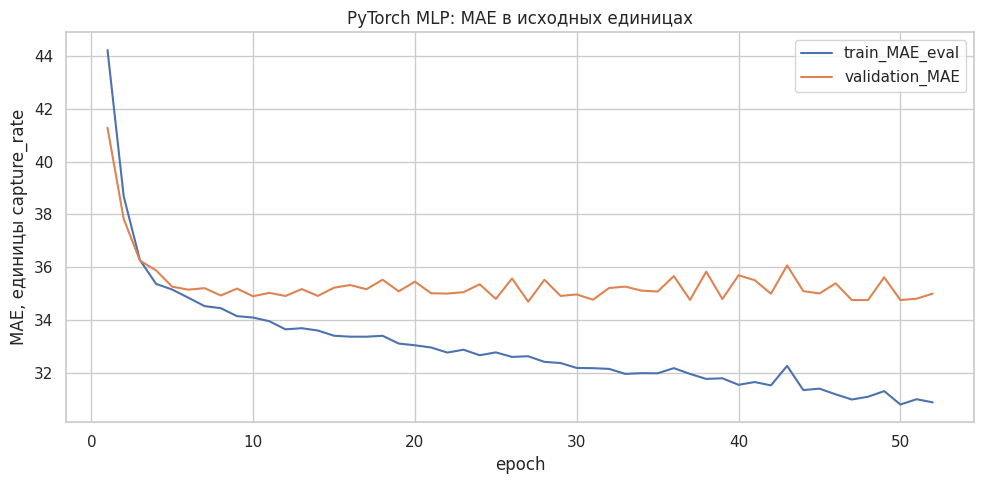

In [ ]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

feature_scaler = StandardScaler()
target_scaler = StandardScaler()

X_train = feature_scaler.fit_transform(
    train[FEATURES]
).astype("float32")

X_val = feature_scaler.transform(
    val[FEATURES]
).astype("float32")

y_train_scaled = target_scaler.fit_transform(
    train[[TARGET]]
).astype("float32")

# Для validation используются только параметры scaler из train.
y_val_scaled = target_scaler.transform(
    val[[TARGET]]
).astype("float32")

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train_scaled),
)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
)

X_train_tensor = torch.from_numpy(X_train).to(DEVICE)
X_val_tensor = torch.from_numpy(X_val).to(DEVICE)

mlp = nn.Sequential(
    nn.Linear(len(FEATURES), 64),
    nn.ReLU(),
    nn.Dropout(0.1),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
).to(DEVICE)

criterion = nn.L1Loss()

optimizer = torch.optim.Adam(
    mlp.parameters(),
    lr=LEARNING_RATE,
)

history_rows = []
best_val_mae = float("inf")
best_state = None
best_epoch = 0
waiting = 0

for epoch in range(1, MAX_EPOCHS + 1):
    mlp.train()
    total_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()
        prediction_scaled = mlp(xb)

        loss = criterion(prediction_scaled, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    mlp.eval()

    with torch.no_grad():
        train_prediction_scaled = (
            mlp(X_train_tensor).cpu().numpy()
        )
        val_prediction_scaled = (
            mlp(X_val_tensor).cpu().numpy()
        )

    train_prediction = target_scaler.inverse_transform(
        train_prediction_scaled
    ).ravel()

    val_prediction = target_scaler.inverse_transform(
        val_prediction_scaled
    ).ravel()

    train_mae = mean_absolute_error(
        train[TARGET], train_prediction
    )
    val_mae = mean_absolute_error(
        val[TARGET], val_prediction
    )

    history_rows.append({
        "epoch": epoch,
        "train_scaled_loss": total_loss / len(train_dataset),
        "train_MAE_eval": train_mae,
        "validation_MAE": val_mae,
    })

    if val_mae < best_val_mae:
        best_val_mae = val_mae
        best_state = copy.deepcopy(mlp.state_dict())
        best_epoch = epoch
        waiting = 0
    else:
        waiting += 1

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"train MAE={train_mae:.2f} | "
            f"validation MAE={val_mae:.2f}"
        )

    if waiting >= PATIENCE:
        print(f"Ранняя остановка на эпохе {epoch}")
        break

mlp.load_state_dict(best_state)
mlp.eval()

print(
    f"Лучшая эпоха: {best_epoch}; "
    f"validation MAE: {best_val_mae:.2f}"
)

history = pd.DataFrame(history_rows)

history.to_csv(
    OUTPUT_DIR / "mlp_history.csv",
    index=False,
)

history.plot(
    x="epoch",
    y=["train_MAE_eval", "validation_MAE"],
    figsize=(10, 5),
)
plt.title("PyTorch MLP: MAE в исходных единицах")
plt.ylabel("MAE, единицы capture_rate")
save_plot("05_mlp_mae.png")

# Обе кривые MAE рассчитаны в режиме eval:
# Dropout отключён при оценке train и validation.

In [ ]:
def predict_mlp(part):
    X = feature_scaler.transform(
        part[FEATURES]
    ).astype("float32")

    mlp.eval()

    with torch.no_grad():
        scaled_prediction = (
            mlp(torch.from_numpy(X).to(DEVICE))
            .cpu()
            .numpy()
        )

    return target_scaler.inverse_transform(
        scaled_prediction
    ).ravel()


def predict_models(part):
    return {
        "Dummy median": baseline_median.predict(part[FEATURES]),
        "Dummy mean": baseline_mean.predict(part[FEATURES]),
        "SVR RBF": svr.predict(part[FEATURES]),
        "PyTorch MLP": predict_mlp(part),
    }


metric_rows = []
validation_predictions = None

for split_name, part in {
    "train": train,
    "validation": val,
}.items():
    predictions = predict_models(part)

    if split_name == "validation":
        validation_predictions = predictions

    for model_name, prediction in predictions.items():
        metric_rows.append({
            "split": split_name,
            "model": model_name,
            **regression_metrics(part[TARGET], prediction),
        })

metrics = pd.DataFrame(metric_rows)

print("Метрики train и validation:")
display(metrics.round(3))

metrics.to_csv(
    OUTPUT_DIR / "train_validation_metrics.csv",
    index=False,
)

validation_metrics = metrics.loc[
    metrics["split"] == "validation"
].copy()

print("Сравнение моделей по validation MAE:")
display(
    validation_metrics.sort_values("MAE").round(3)
)

# Рекомендуемый обучаемый кандидат.
trained_candidates = validation_metrics.loc[
    validation_metrics["model"].isin(["SVR RBF", "PyTorch MLP"])
]

recommended_model = trained_candidates.sort_values(
    "MAE", kind="stable"
).iloc[0]["model"]

best_baseline_mae = validation_metrics.loc[
    validation_metrics["model"].str.startswith("Dummy"),
    "MAE",
].min()

recommended_mae = trained_candidates.loc[
    trained_candidates["model"] == recommended_model,
    "MAE",
].iloc[0]

print("Лучший обучаемый кандидат:", recommended_model)

if recommended_mae >= best_baseline_mae:
    print(
        "Внимание: лучший обучаемый кандидат "
        "не превзошёл лучший baseline по validation MAE."
    )
else:
    print(
        "Улучшение относительно лучшего baseline:",
        round(best_baseline_mae - recommended_mae, 2),
        "единиц MAE",
    )

Метрики train и validation:


,split,model,MAE,RMSE,R2,outside_0_255
0,train,Dummy median,58.565,84.173,-0.222,0
1,train,Dummy mean,64.071,76.136,0.000,0
2,train,SVR RBF,33.694,50.325,0.563,3
3,train,PyTorch MLP,32.629,49.938,0.570,2
4,validation,Dummy median,52.619,75.841,-0.153,0
5,validation,Dummy mean,60.329,71.097,-0.014,0
6,validation,SVR RBF,35.647,51.301,0.472,2
7,validation,PyTorch MLP,34.696,50.725,0.484,4


Сравнение моделей по validation MAE:


,split,model,MAE,RMSE,R2,outside_0_255
7,validation,PyTorch MLP,34.696,50.725,0.484,4
6,validation,SVR RBF,35.647,51.301,0.472,2
4,validation,Dummy median,52.619,75.841,-0.153,0
5,validation,Dummy mean,60.329,71.097,-0.014,0


Лучший обучаемый кандидат: PyTorch MLP
Улучшение относительно лучшего baseline: 17.92 единиц MAE



validation: Dummy median
Ошибки по диапазонам:


,count,MAE,mean_residual,model
target_range,,,,
0–30,24,48.62,-48.62,Dummy median
31–100,90,16.11,-2.33,Dummy median
101–200,34,104.18,104.18,Dummy median
201–255,12,188.33,188.33,Dummy median


Наибольшие ошибки:


,pokedex_number,name,evolution_chain_id,capture_rate,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,prediction,residual,absolute_error,target_range
40,41,Zubat,17,255,40,45,35,30,40,55,0.8,7.5,60.0,195.0,195.0,201–255
68,69,Bellsprout,29,255,50,75,35,70,30,40,0.7,4.0,60.0,195.0,195.0,201–255
160,161,Sentret,82,255,35,46,34,35,45,20,0.8,6.0,60.0,195.0,195.0,201–255
858,859,Impidimp,451,255,45,45,30,55,40,50,0.4,5.5,60.0,195.0,195.0,201–255
395,396,Starly,206,255,40,55,30,30,30,60,0.3,2.0,60.0,195.0,195.0,201–255
435,436,Bronzor,224,255,57,24,86,24,86,23,0.5,60.5,60.0,195.0,195.0,201–255
284,285,Shroomish,142,255,60,40,60,40,60,35,0.4,4.5,60.0,195.0,195.0,201–255
327,328,Trapinch,166,255,45,100,45,45,45,10,0.7,15.0,60.0,195.0,195.0,201–255
830,831,Wooloo,438,255,42,40,55,40,45,48,0.6,6.0,60.0,195.0,195.0,201–255
760,761,Bounsweet,392,235,42,30,38,30,38,32,0.3,3.2,60.0,175.0,175.0,201–255



validation: Dummy mean
Ошибки по диапазонам:


,count,MAE,mean_residual,model
target_range,,,,
0–30,24,84.52,-84.52,Dummy mean
31–100,90,38.59,-38.23,Dummy mean
101–200,34,68.28,68.28,Dummy mean
201–255,12,152.44,152.44,Dummy mean


... (8 outputs left out)

Наибольшие ошибки:


,pokedex_number,name,evolution_chain_id,capture_rate,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,prediction,residual,absolute_error,target_range
745,746,Wishiwashi-Solo,384,60,45,20,20,25,25,40,0.2,0.3,255.982651,-195.982651,195.982651,31–100
884,885,Dreepy,466,45,28,60,30,40,30,82,0.5,2.0,205.479019,-160.479019,160.479019,31–100
966,967,Cyclizar,506,190,70,95,65,85,65,121,1.6,63.0,52.461189,137.538811,137.538811,101–200
809,810,Grookey,430,45,50,65,50,40,40,65,0.3,5.0,180.251816,-135.251816,135.251816,31–100
812,813,Scorbunny,431,45,50,71,40,40,40,69,0.3,4.5,174.917557,-129.917557,129.917557,31–100
632,633,Deino,323,45,52,65,50,45,50,38,0.8,17.3,171.381409,-126.381409,126.381409,31–100
586,587,Emolga,298,200,55,75,60,75,60,103,0.4,5.0,74.091515,125.908485,125.908485,101–200
157,158,Totodile,81,45,50,65,64,44,48,43,0.6,9.5,170.659164,-125.659164,125.659164,31–100
3,4,Charmander,2,45,39,52,43,60,50,65,0.6,8.5,170.510345,-125.510345,125.510345,31–100
389,390,Chimchar,204,45,44,58,44,58,44,61,0.5,6.2,169.876709,-124.876709,124.876709,31–100



Сводка ошибок:


,model,MAE,median_absolute_error,p90_absolute_error,mean_residual
0,Dummy median,52.62,30.00,131.00,27.66
1,Dummy mean,60.33,50.89,95.11,-8.24
2,SVR RBF,35.65,21.51,85.94,-6.09
3,PyTorch MLP,34.70,23.29,88.64,-4.32


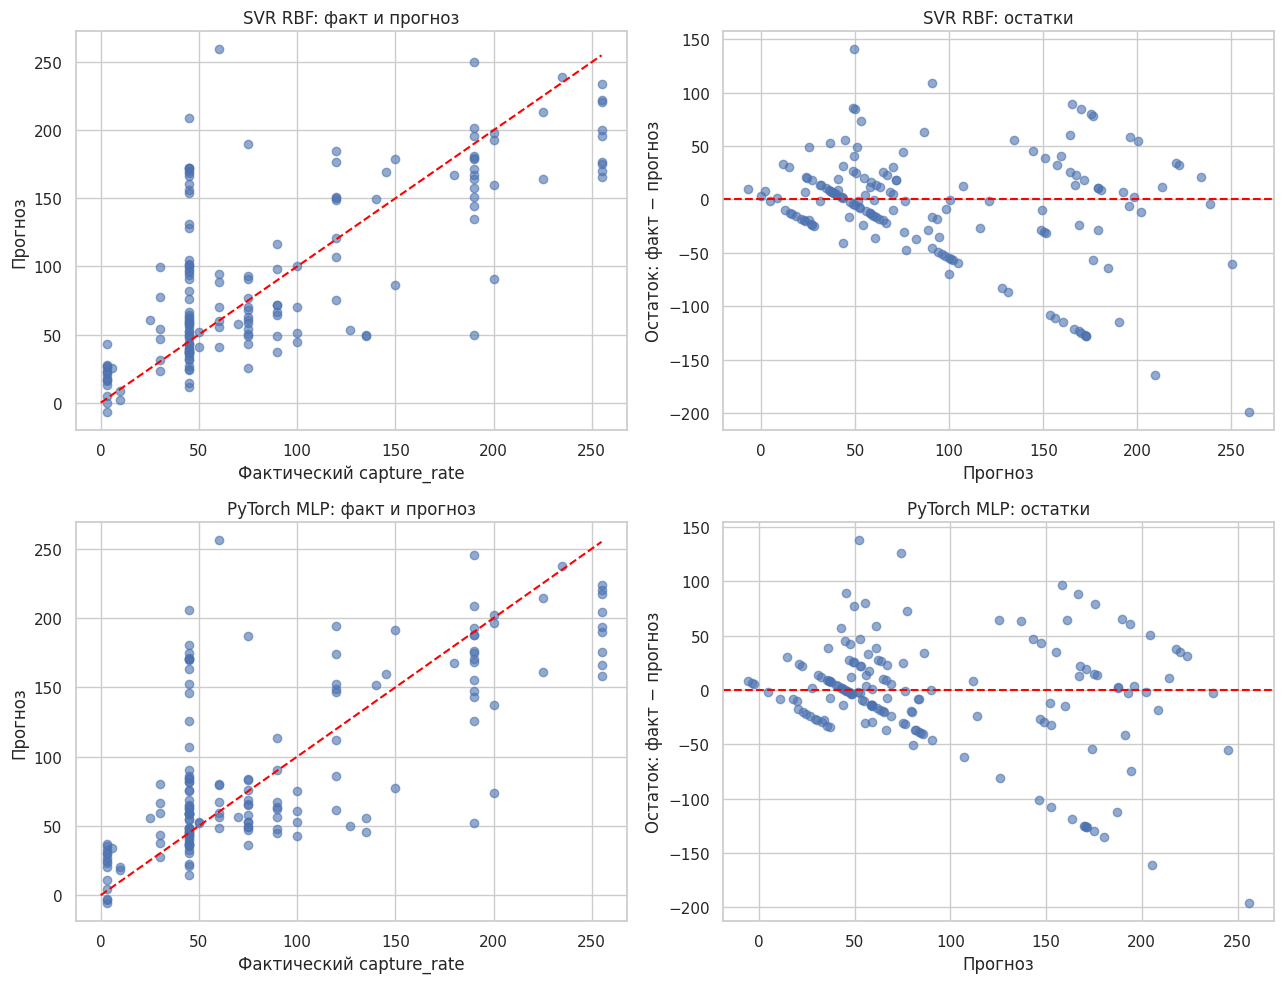

In [ ]:
def analyze_errors(part, predictions, split_name):
    summaries = []
    range_tables = []

    for model_name, prediction in predictions.items():
        safe_name = model_name.lower().replace(" ", "_")

        analysis = part[
            ["pokedex_number", "name", GROUP, TARGET, *FEATURES]
        ].copy()

        analysis["prediction"] = prediction

        # Положительный остаток: прогноз ниже фактического значения.
        analysis["residual"] = (
            analysis[TARGET] - analysis["prediction"]
        )
        analysis["absolute_error"] = analysis["residual"].abs()

        summaries.append({
            "model": model_name,
            "MAE": analysis["absolute_error"].mean(),
            "median_absolute_error": analysis["absolute_error"].median(),
            "p90_absolute_error": analysis["absolute_error"].quantile(0.9),
            "mean_residual": analysis["residual"].mean(),
        })

        analysis["target_range"] = pd.cut(
            analysis[TARGET],
            bins=RANGE_BINS,
            labels=RANGE_LABELS,
        )

        range_summary = (
            analysis.groupby("target_range", observed=True)
            .agg(
                count=("absolute_error", "size"),
                MAE=("absolute_error", "mean"),
                mean_residual=("residual", "mean"),
            )
            .reindex(RANGE_LABELS)
        )

        range_summary["count"] = (
            range_summary["count"].fillna(0).astype(int)
        )
        # Для пустых диапазонов MAE остаётся NaN, не ноль.
        range_summary["model"] = model_name
        range_tables.append(range_summary.reset_index())

        print("\n" + "=" * 60)
        print(f"{split_name}: {model_name}")

        print("Ошибки по диапазонам:")
        display(range_summary.round(2))

        print("Наибольшие ошибки:")
        display(
            analysis.sort_values(
                "absolute_error", ascending=False
            ).head(15)
        )

        analysis.to_csv(
            OUTPUT_DIR / f"{split_name}_{safe_name}_predictions.csv",
            index=False,
            encoding="utf-8-sig",
        )

    error_summary = pd.DataFrame(summaries)
    range_summary_all = pd.concat(range_tables, ignore_index=True)

    print("\nСводка ошибок:")
    display(error_summary.round(2))

    error_summary.to_csv(
        OUTPUT_DIR / f"{split_name}_error_summary.csv",
        index=False,
    )

    range_summary_all.to_csv(
        OUTPUT_DIR / f"{split_name}_errors_by_range.csv",
        index=False,
        encoding="utf-8-sig",
    )


analyze_errors(
    val,
    validation_predictions,
    "validation",
)

# Визуализируем ошибки обеих обучаемых моделей.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for row, model_name in enumerate(["SVR RBF", "PyTorch MLP"]):
    prediction = validation_predictions[model_name]
    residual = val[TARGET].to_numpy() - prediction

    axes[row, 0].scatter(
        val[TARGET], prediction, alpha=0.6
    )
    axes[row, 0].plot(
        [0, 255], [0, 255], "--", color="red"
    )
    axes[row, 0].set_xlabel("Фактический capture_rate")
    axes[row, 0].set_ylabel("Прогноз")
    axes[row, 0].set_title(f"{model_name}: факт и прогноз")

    axes[row, 1].scatter(
        prediction, residual, alpha=0.6
    )
    axes[row, 1].axhline(
        0, color="red", linestyle="--"
    )
    axes[row, 1].set_xlabel("Прогноз")
    axes[row, 1].set_ylabel("Остаток: факт − прогноз")
    axes[row, 1].set_title(f"{model_name}: остатки")

save_plot("06_validation_predictions_and_residuals.png")

In [ ]:
joblib.dump(
    {
        "baseline_median": baseline_median,
        "baseline_mean": baseline_mean,
        "svr": svr,
        "mlp_feature_scaler": feature_scaler,
        "mlp_target_scaler": target_scaler,
        "features": FEATURES,
        "target": TARGET,
        "recommended_model": recommended_model,
        "seed": SEED,
    },
    OUTPUT_DIR / "regression_models.joblib",
)

torch.save(
    {
        "state_dict": mlp.state_dict(),
        "input_dim": len(FEATURES),
        "features": FEATURES,
        "target": TARGET,
        "best_epoch": best_epoch,
        "seed": SEED,
        "dropout": 0.1,
    },
    OUTPUT_DIR / "mlp_checkpoint.pt",
)

print("Модели сохранены:", OUTPUT_DIR)

# Загружайте joblib и checkpoint только из доверенных источников.

Модели сохранены: /content/drive/MyDrive/regression_results_A


In [ ]:
RUN_TEST = False

if RUN_TEST:
    test_predictions = predict_models(test)

    test_metrics = pd.DataFrame([
        {
            "model": model_name,
            **regression_metrics(test[TARGET], prediction),
        }
        for model_name, prediction in test_predictions.items()
    ])

    print("Итоговая оценка на test:")
    display(test_metrics.round(3))

    test_metrics.to_csv(
        OUTPUT_DIR / "test_metrics.csv",
        index=False,
    )

    analyze_errors(test, test_predictions, "test")

    print(
        "Кандидат был выбран по validation:",
        recommended_model,
    )

    print(
        "После просмотра test параметры не подбираются."
    )
else:
    print(
        "Test не оценивался. "
        "Сначала анализируем train и validation."
    )

Test не оценивался. Сначала анализируем train и validation.


Анализ ошибок по диапазонам выявил систематическое завышение низких и занижение высоких значений capture_rate обеими моделями. Наибольшая средняя абсолютная ошибка наблюдается в диапазоне 201–255 — около 51 единицы, однако основная доля общей ошибки приходится на диапазон 31–100 из-за его высокой представленности.

MLP уступает SVR в трёх диапазонах, но лучше предсказывает наиболее многочисленный диапазон 31–100, что обеспечивает небольшое преимущество по общей MAE. Медианный baseline лучше моделей внутри этого диапазона, но значительно хуже на высоких значениях. Полученные результаты указывают на необходимость проверки дополнительных категориальных признаков, способных уточнить предсказание игровой характеристики.